# Task 1: Exploratory Data Analysis (EDA) on Superstore Retail Sales

**Internship:** Datheon – Data Analytics  
**Deliverable:** Cleaned and analyzed Jupyter Notebook  
**Dataset:** Superstore Retail Sales (provided CSV)

## Objective
Clean the supplied retail-sales data, profile missing values, analyze customer purchase volume and sales seasonality, compare category/region/customer-segment performance, investigate discount sensitivity, and document actionable business findings.

> This notebook is self-contained: the supplied CSV is embedded in compressed form, so no separate dataset file is needed to run it.

In [ ]:
# 1. Import libraries and load the supplied dataset
import base64
import gzip
import io
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Embedded compressed source CSV (self-contained notebook)
DATA_B64 = '''...'''

csv_content = gzip.decompress(base64.b64decode(DATA_B64))
raw_df = pd.read_csv(io.BytesIO(csv_content))

print(f"Raw dataset shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())


Raw dataset shape: 10,800 rows × 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 2. Initial data inspection

Inspect data types, descriptive statistics, null counts, and the unusual rows in the supplied file. The source contains appended non-record rows with missing order dates; these are excluded from the analytical dataset.

In [ ]:
print("Column data types:")
display(raw_df.dtypes.to_frame("Data type"))

print("\\nMissing values in the raw file:")
missing_raw = raw_df.isna().sum().sort_values(ascending=False)
display(missing_raw[missing_raw > 0].to_frame("Missing count"))

print("\\nRaw data sample and summary:")
display(raw_df.describe(include="all").T)


Column data types:


,Data type
Row ID,object
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


\nMissing values in the raw file:


,Missing count
Postal Code,817
Ship Mode,806
Ship Date,806
Customer ID,806
Order Date,806
Product ID,806
Category,806
Segment,806
Customer Name,806
Country,806


\nRaw data sample and summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,10800,10001,Yes,800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order ID,10800,5015,CA-2018-100111,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1236,9/5/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2016,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data cleaning and preparation

Cleaning decisions:
1. Parse `Order Date` and `Ship Date` using month/day/year date interpretation.
2. Remove rows with an invalid or missing `Order Date`. In this supplied file, these are appended non-record rows (their `Row ID` is not numeric and the other transaction fields are blank).
3. Convert numeric analysis fields to numeric types.
4. Keep the 11 missing postal codes as null: postal code is not needed for the requested sales/profit analysis, and filling it would invent location data.
5. Check duplicate transaction rows and create `Year`, `Month`, and `Year-Month` fields.

In [3]:
# Parse dates; invalid/missing order dates identify non-transaction rows in this file
df = raw_df.copy()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

rows_before = len(df)
df = df.dropna(subset=["Order Date"]).copy()
rows_removed = rows_before - len(df)

numeric_cols = ["Postal Code", "Sales", "Quantity", "Discount", "Profit"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

duplicate_count = int(df.duplicated().sum())
if duplicate_count:
    df = df.drop_duplicates().copy()

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows removed (invalid/missing Order Date): {rows_removed:,}")
print(f"Exact duplicate rows found: {duplicate_count:,}")
print(f"Cleaned dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Remaining missing postal codes: {df['Postal Code'].isna().sum():,}")
display(df.head())


Rows before cleaning: 10,800
Rows removed (invalid/missing Order Date): 806
Exact duplicate rows found: 0
Cleaned dataset shape: 9,994 rows × 25 columns
Remaining missing postal codes: 11


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Year-Month
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017,11,Nov,2017-11
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017,11,Nov,2017-11
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017,6,Jun,2017-06
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016,10,Oct,2016-10
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016,10,Oct,2016-10


## 4. Data quality profile

Confirm that the cleaned data has no missing values in the fields required for the requested analysis. Postal Code remains the only field with missing values.

In [4]:
quality = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique(dropna=True)
})
display(quality)

required_fields = ["Order ID", "Order Date", "Segment", "Region", "Category",
                   "Sub-Category", "Sales", "Quantity", "Discount", "Profit"]
print("Missing values in required analysis fields:",
      int(df[required_fields].isna().sum().sum()))


,Missing values,Missing %,Unique values
Row ID,0,0.00,9994
Order ID,0,0.00,5009
Order Date,0,0.00,1236
Ship Date,0,0.00,1334
Ship Mode,0,0.00,4
Customer ID,0,0.00,793
Customer Name,0,0.00,793
Segment,0,0.00,3
Country,0,0.00,1
City,0,0.00,531


Missing values in required analysis fields: 0


## 5. Key business KPIs

The following KPIs summarize transaction volume, customer reach, revenue, profit, and average order value. Sales and profit are reported in the dataset's currency (USD).

In [5]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
order_count = df["Order ID"].nunique()
customer_count = df["Customer ID"].nunique()
avg_order_value = total_sales / order_count if order_count else np.nan
profit_margin = (total_profit / total_sales * 100) if total_sales else np.nan

kpis = pd.DataFrame({
    "Metric": ["Total Sales", "Total Profit", "Units Sold", "Distinct Orders",
               "Distinct Customers", "Average Sales per Order", "Overall Profit Margin"],
    "Value": [total_sales, total_profit, total_quantity, order_count,
              customer_count, avg_order_value, profit_margin]
})
display(kpis.style.format({"Value": lambda x: f"{x:,.2f}"}))


,Metric,Value
0,Total Sales,"2,297,200.86"
1,Total Profit,"286,397.02"
2,Units Sold,"37,873.00"
3,Distinct Orders,"5,009.00"
4,Distinct Customers,793.00
5,Average Sales per Order,458.61
6,Overall Profit Margin,12.47


## 6. Customer purchase volume and segment analysis

Compare sales, profit, order count, and quantity across Consumer, Corporate, and Home Office customer segments.

,Sales,Profit,Quantity,Orders,Customers
Segment,,,,,
Consumer,"1,161,401.34","134,119.21","19,521.00","2,586.00",409.00
Corporate,"706,146.37","91,979.13","11,608.00","1,514.00",236.00
Home Office,"429,653.15","60,298.68","6,744.00",909.00,148.00


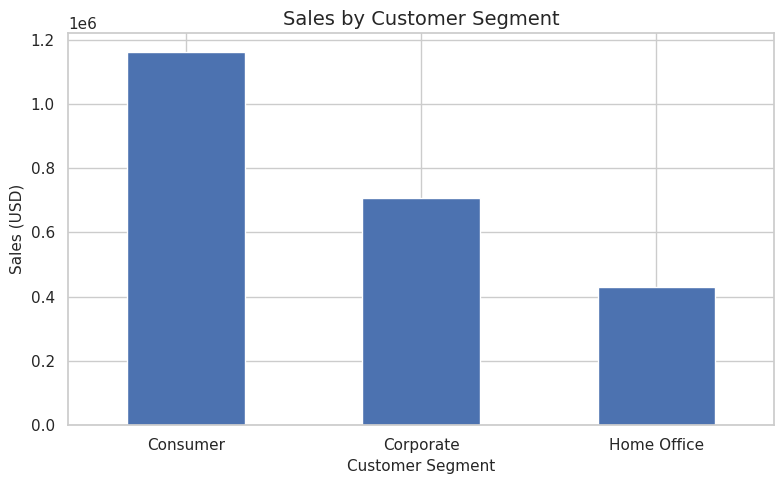

In [6]:
segment_summary = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum"),
    Orders=("Order ID", "nunique"),
    Customers=("Customer ID", "nunique")
).sort_values("Sales", ascending=False)
display(segment_summary.style.format("{:,.2f}"))

ax = segment_summary["Sales"].plot(kind="bar", figsize=(8, 5), title="Sales by Customer Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Sales (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Monthly sales seasonality

Aggregate sales by calendar month and visualize the monthly trend. The time series covers the order dates in the supplied dataset.

,Sales
Year-Month,
2018-01,"43,971.37"
2018-02,"20,301.13"
2018-03,"58,872.35"
2018-04,"36,521.54"
2018-05,"44,261.11"
2018-06,"52,981.73"
2018-07,"45,264.42"
2018-08,"63,120.89"
2018-09,"87,866.65"


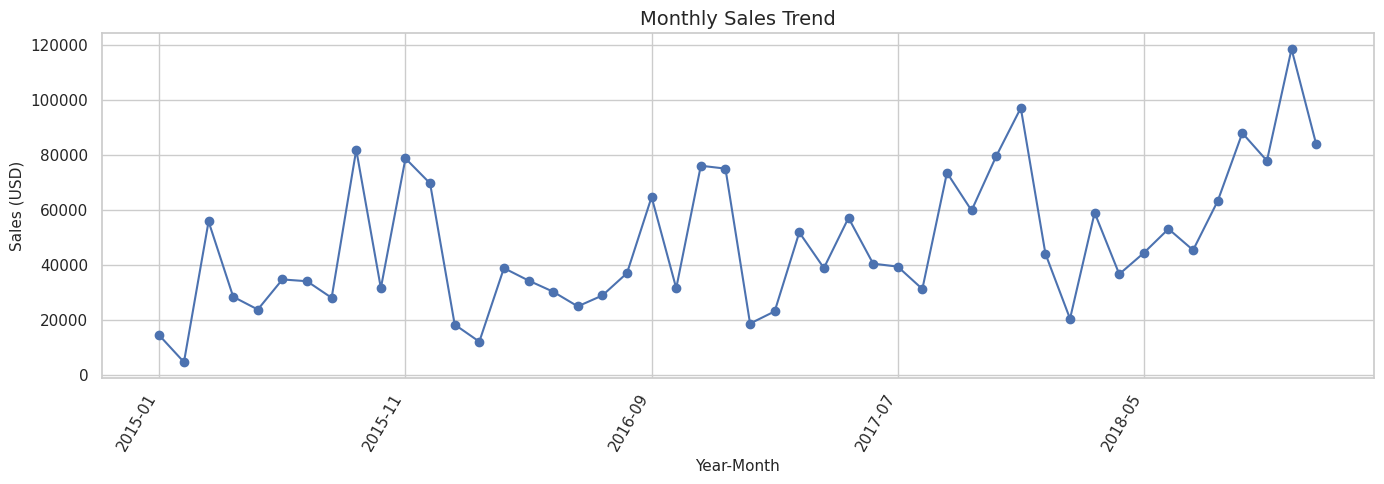

In [7]:
monthly_sales = df.groupby("Year-Month", as_index=True)["Sales"].sum().sort_index()
display(monthly_sales.to_frame("Sales").tail(12).style.format("{:,.2f}"))

ax = monthly_sales.plot(marker="o", linewidth=1.5, figsize=(14, 5),
                        title="Monthly Sales Trend")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Sales (USD)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

peak_month = monthly_sales.idxmax()
peak_sales = monthly_sales.max()
lowest_month = monthly_sales.idxmin()
lowest_sales = monthly_sales.min()


## 8. Category-wise and sub-category performance

Compare total sales and profit by product category. A separate sub-category profit ranking helps identify areas of loss.

,Sales,Profit,Quantity
Category,,,
Technology,"836,154.03","145,454.95","6,939.00"
Furniture,"741,999.80","18,451.27","8,028.00"
Office Supplies,"719,047.03","122,490.80","22,906.00"


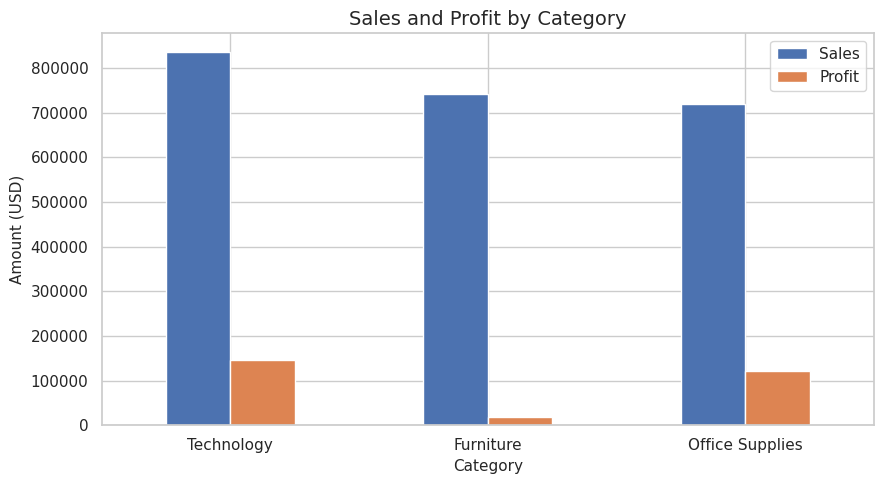

,Total Profit
Sub-Category,
Tables,"-17,725.48"
Bookcases,"-3,472.56"
Supplies,"-1,189.10"
Fasteners,949.52
Machines,"3,384.76"
Labels,"5,546.25"
Art,"6,527.79"
Envelopes,"6,964.18"
Furnishings,"13,059.14"


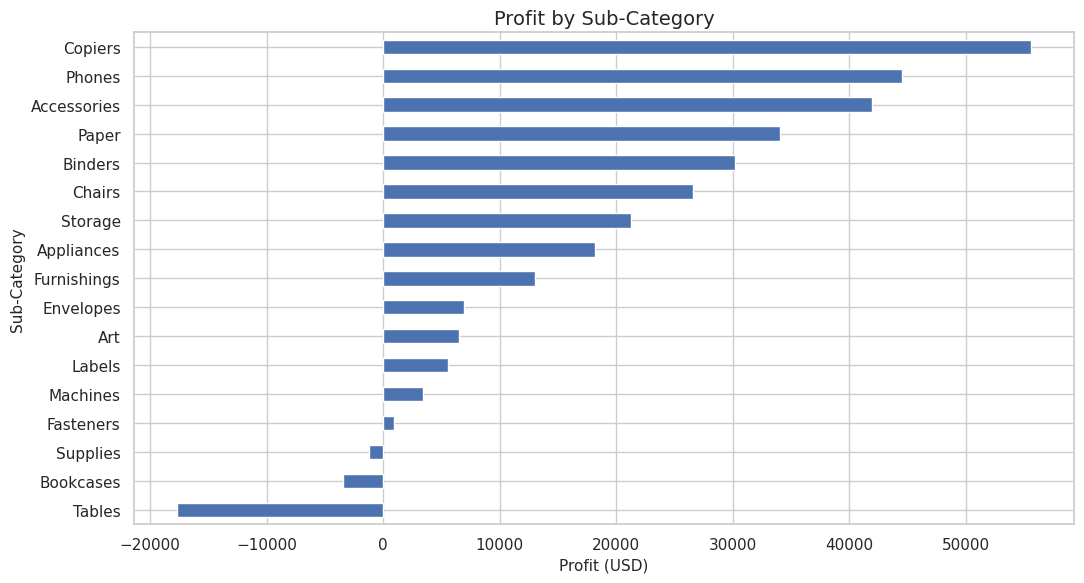

In [8]:
category_summary = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum")
).sort_values("Sales", ascending=False)
display(category_summary.style.format("{:,.2f}"))

category_summary[["Sales", "Profit"]].plot(kind="bar", figsize=(9, 5),
                                           title="Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

subcategory_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()
display(subcategory_profit.to_frame("Total Profit").style.format("{:,.2f}"))

plt.figure(figsize=(11, 6))
subcategory_profit.plot(kind="barh", title="Profit by Sub-Category")
plt.xlabel("Profit (USD)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()


## 9. Region-wise sales and profit

Rank the four sales regions by revenue and compare their profitability.

,Sales,Profit,Orders
Region,,,
West,"725,457.82","108,418.45","1,611.00"
East,"678,781.24","91,522.78","1,401.00"
Central,"501,239.89","39,706.36","1,175.00"
South,"391,721.91","46,749.43",822.00


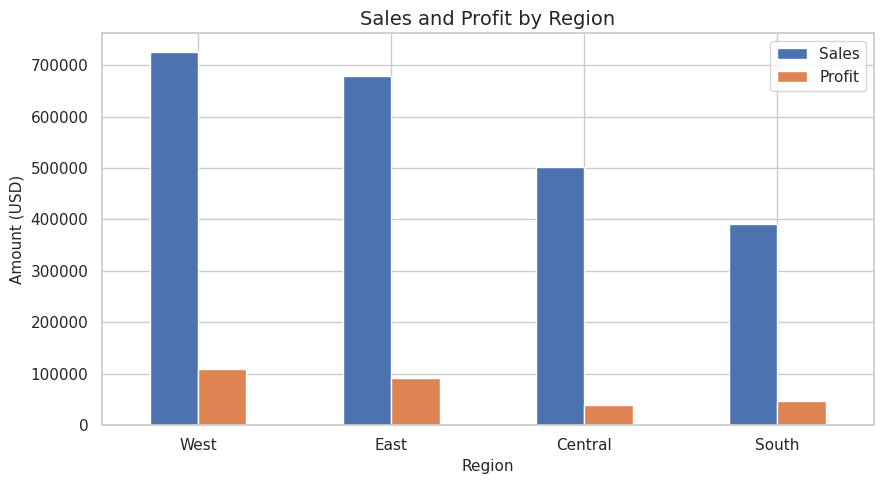

In [9]:
region_summary = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).sort_values("Sales", ascending=False)
display(region_summary.style.format("{:,.2f}"))

region_summary[["Sales", "Profit"]].plot(kind="bar", figsize=(9, 5),
                                         title="Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

top_region = region_summary.index[0]
top_region_sales = region_summary.iloc[0]["Sales"]


## 10. Discount sensitivity and profitability

Examine the relationship between discount and profit. Correlation describes association, not causation. The discount-level table includes transaction counts to provide context.

,Transactions,Average_Profit,Total_Profit,Average_Sales
Discount,,,,
0.000000,4798,66.90,"320,987.60",226.74
0.100000,94,96.06,"9,029.18",578.40
0.150000,52,27.29,"1,418.99",529.97
0.200000,3657,24.70,"90,337.31",209.08
0.300000,227,-45.68,"-10,369.28",454.74
0.320000,27,-88.56,"-2,391.14",536.79
0.400000,206,-111.93,"-23,057.05",565.13
0.450000,11,-226.65,"-2,493.11",498.63
0.500000,66,-310.70,"-20,506.43",892.71


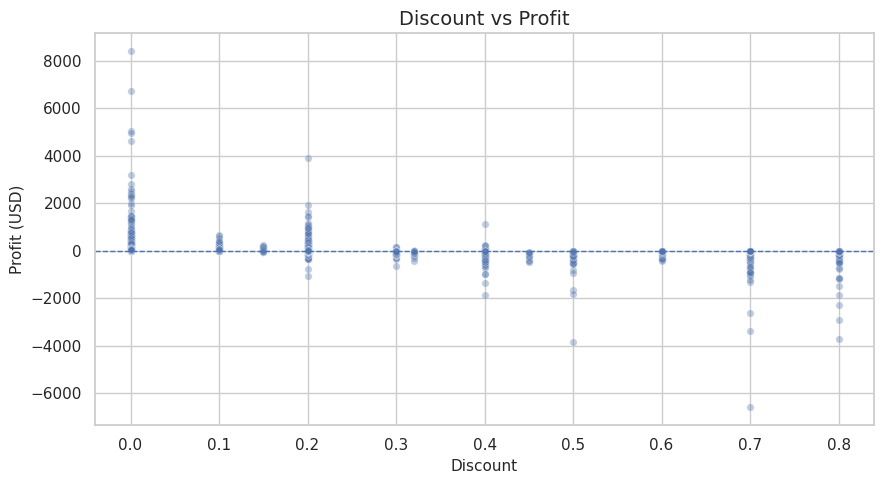

Pearson correlation between Discount and Profit: -0.219


In [10]:
discount_corr = df[["Discount", "Profit"]].corr().loc["Discount", "Profit"]
discount_summary = df.groupby("Discount").agg(
    Transactions=("Profit", "size"),
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Average_Sales=("Sales", "mean")
).sort_index()
display(discount_summary.style.format({
    "Average_Profit": "{:,.2f}", "Total_Profit": "{:,.2f}", "Average_Sales": "{:,.2f}"
}))

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.35, s=28)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit (USD)")
plt.tight_layout()
plt.show()

print(f"Pearson correlation between Discount and Profit: {discount_corr:.3f}")


## 11. Five annotated business findings and recommendations

The findings below are calculated from the cleaned dataset. The discount finding is phrased as an association rather than a causal claim.

In [11]:
consumer_sales = segment_summary.loc["Consumer", "Sales"] if "Consumer" in segment_summary.index else np.nan
technology_profit = category_summary.loc["Technology", "Profit"] if "Technology" in category_summary.index else np.nan
tables_profit = subcategory_profit.get("Tables", np.nan)
loss_subcats = int((subcategory_profit < 0).sum())

findings = [
    (f"Revenue and scale",
     f"The cleaned dataset contains {len(df):,} valid line-item records across {order_count:,} distinct orders and {customer_count:,} customers, generating ${total_sales:,.2f} in sales and ${total_profit:,.2f} in profit.",
     "Use order- and customer-level KPIs as a baseline for future performance tracking."),
    (f"Technology profitability",
     f"Technology is the highest-sales category (${category_summary.loc['Technology', 'Sales']:,.2f}) and generated ${technology_profit:,.2f} in profit.",
     "Protect availability and service quality for strong-performing technology products while monitoring margin by sub-category."),
    (f"Regional performance",
     f"{top_region} is the largest region by sales, contributing ${top_region_sales:,.2f}.",
     "Review the leading region's product mix and operating practices, then compare them with lower-sales regions to identify transferable opportunities."),
    (f"Customer segment mix",
     f"Consumer is the largest segment by sales, contributing ${consumer_sales:,.2f} of the total.",
     "Prioritize retention and relevant product recommendations for Consumer customers while developing targeted growth plans for Corporate and Home Office."),
    (f"Discount and profit relationship",
     f"Discount and profit have a Pearson correlation of {discount_corr:.3f}. {loss_subcats} sub-categories have negative total profit; Tables has the lowest total profit (${tables_profit:,.2f}).",
     "Review discount approval rules and the economics of loss-making sub-categories. Test changes with controlled comparisons before drawing causal conclusions.")
]

for i, (heading, evidence, recommendation) in enumerate(findings, 1):
    display(Markdown(f"### Finding {i}: {heading}\\n\\n**Evidence:** {evidence}\\n\\n**Recommended action:** {recommendation}"))


### Finding 1: Revenue and scale\n\n**Evidence:** The cleaned dataset contains 9,994 valid line-item records across 5,009 distinct orders and 793 customers, generating $2,297,200.86 in sales and $286,397.02 in profit.\n\n**Recommended action:** Use order- and customer-level KPIs as a baseline for future performance tracking.

### Finding 2: Technology profitability\n\n**Evidence:** Technology is the highest-sales category ($836,154.03) and generated $145,454.95 in profit.\n\n**Recommended action:** Protect availability and service quality for strong-performing technology products while monitoring margin by sub-category.

### Finding 3: Regional performance\n\n**Evidence:** West is the largest region by sales, contributing $725,457.82.\n\n**Recommended action:** Review the leading region's product mix and operating practices, then compare them with lower-sales regions to identify transferable opportunities.

### Finding 4: Customer segment mix\n\n**Evidence:** Consumer is the largest segment by sales, contributing $1,161,401.34 of the total.\n\n**Recommended action:** Prioritize retention and relevant product recommendations for Consumer customers while developing targeted growth plans for Corporate and Home Office.

### Finding 5: Discount and profit relationship\n\n**Evidence:** Discount and profit have a Pearson correlation of -0.219. 3 sub-categories have negative total profit; Tables has the lowest total profit ($-17,725.48).\n\n**Recommended action:** Review discount approval rules and the economics of loss-making sub-categories. Test changes with controlled comparisons before drawing causal conclusions.

## 12. Conclusion

This EDA established a clean transaction-level dataset, quantified overall performance, and explored monthly sales, customer segments, product categories, regions, and discount/profit relationships. The analysis highlights opportunities to protect profitable categories, learn from the strongest region, deepen engagement with the largest customer segment, and review discounts and loss-making sub-categories.

**Limitations:** This is descriptive analysis of the supplied historical dataset. It does not establish why sales or profit changed, and correlation does not prove causation. Further work could include cohort analysis, forecasting, and controlled discount experiments.